In [1]:
from pathlib import Path
import random

import albumentations as A
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from albumentations.pytorch import ToTensorV2
from torch.utils.data import DataLoader, Dataset

In [14]:
SEED = 42
IMAGE_SIZE = 256
BATCH_SIZE = 16
EPOCHS = 10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_ROOT = Path("../brisc2025")
SPLIT_ROOT = Path("../data")
CHECKPOINT_ROOT = Path("../checkpoints")
CHECKPOINT_ROOT.mkdir(exist_ok=True)

device = (
    torch.device("cuda") if torch.cuda.is_available()
    else torch.device("mps") if torch.backends.mps.is_available()
    else torch.device("cpu")
)

print("Device:", device)

Device: mps


In [3]:
train_df = pd.read_csv(SPLIT_ROOT / "segmentation_train.csv")
val_df = pd.read_csv(SPLIT_ROOT / "segmentation_val.csv")

print("Full training samples:", len(train_df))
print("Full validation samples:", len(val_df))

Full training samples: 3146
Full validation samples: 787


In [4]:
train_transform = A.Compose([
    A.Resize(IMAGE_SIZE, IMAGE_SIZE),
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=10, border_mode=cv2.BORDER_CONSTANT, p=0.5),
    A.Normalize(mean=(0.5,), std=(0.5,)),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Resize(IMAGE_SIZE, IMAGE_SIZE),
    A.Normalize(mean=(0.5,), std=(0.5,)),
    ToTensorV2(),
])

In [5]:
class SegmentationDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_path = DATA_ROOT / row["relative_path"]
        mask_path = DATA_ROOT / row["mask_relative_path"]

        image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

        if image is None or mask is None:
            raise FileNotFoundError(f"Could not load {image_path} or {mask_path}")

        mask = (mask > 0).astype(np.float32)
        transformed = self.transform(image=image, mask=mask)
        
        image = transformed["image"].float()
        mask = transformed["mask"].float()

        if mask.ndim == 2:
            mask = mask.unsqueeze(0)

        return image, mask

In [6]:

train_dataset = SegmentationDataset(train_df, train_transform)
val_dataset = SegmentationDataset(val_df, val_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)
images, masks = next(iter(train_loader))

## U-Net


In [7]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.layers(x)


class UNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1, base=16):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.enc1 = DoubleConv(in_channels, base)
        self.enc2 = DoubleConv(base, base * 2)
        self.enc3 = DoubleConv(base * 2, base * 4)
        self.enc4 = DoubleConv(base * 4, base * 8)
        self.bottleneck = DoubleConv(base * 8, base * 16)

        self.up4 = nn.ConvTranspose2d(base * 16, base * 8, 2, stride=2)
        self.dec4 = DoubleConv(base * 16, base * 8)
        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.dec3 = DoubleConv(base * 8, base * 4)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = DoubleConv(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = DoubleConv(base * 2, base)
        self.output = nn.Conv2d(base, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.output(d1)


model = UNet().to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 1,942,289


## metric

In [ ]:
def dice_coefficient(logits, targets, threshold=0.5, smooth=1e-6):
    predictions = (torch.sigmoid(logits) >= threshold).float()
    dims = (1, 2, 3)
    intersection = (predictions * targets).sum(dim=dims)
    denominator = predictions.sum(dim=dims) + targets.sum(dim=dims)
    return ((2 * intersection + smooth) / (denominator + smooth)).mean()


def segmentation_loss(logits, targets, smooth=1e-6):
    bce = F.binary_cross_entropy_with_logits(logits, targets)
    probabilities = torch.sigmoid(logits)
    dims = (1, 2, 3)
    intersection = (probabilities * targets).sum(dim=dims)
    denominator = probabilities.sum(dim=dims) + targets.sum(dim=dims)
    dice_loss = 1 - ((2 * intersection + smooth) / (denominator + smooth)).mean()
    return 0.5 * bce + 0.5 * dice_loss

# test 
with torch.no_grad():
    test_logits = model(images.to(device))

print("Model output:", test_logits.shape)
print("Initial loss:", segmentation_loss(test_logits, masks.to(device)).item())
assert test_logits.shape == masks.shape

Model output: torch.Size([16, 1, 256, 256])
Initial loss: 0.9445729851722717


In [11]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)


def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0
    total_dice = 0.0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = segmentation_loss(logits, masks)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        total_dice += dice_coefficient(logits, masks).item() * images.size(0)

    size = len(loader.dataset)
    return total_loss / size, total_dice / size

In [15]:

best_dice = -1.0

for epoch in range(EPOCHS):
    train_loss, train_dice = run_epoch(train_loader, training=True)
    eval_loss, eval_dice = run_epoch(val_loader, training=False)

    if eval_dice > best_dice:
        best_dice = eval_dice


    print(
        f"Epoch {epoch + 1:02d}: "
        f"train loss={train_loss:.4f}, train Dice={train_dice:.4f}, "
        f"eval loss={eval_loss:.4f}, eval Dice={eval_dice:.4f}"
    )

print(best_dice)

Epoch 01: train loss=0.1720, train Dice=0.7175, eval loss=0.1998, eval Dice=0.6686
Epoch 02: train loss=0.1575, train Dice=0.7394, eval loss=0.1815, eval Dice=0.6956
Epoch 03: train loss=0.1479, train Dice=0.7529, eval loss=0.1965, eval Dice=0.6699
Epoch 04: train loss=0.1459, train Dice=0.7542, eval loss=0.1569, eval Dice=0.7374
Epoch 05: train loss=0.1402, train Dice=0.7631, eval loss=0.1536, eval Dice=0.7394
Epoch 06: train loss=0.1350, train Dice=0.7718, eval loss=0.1486, eval Dice=0.7498
Epoch 07: train loss=0.1295, train Dice=0.7811, eval loss=0.1623, eval Dice=0.7241
Epoch 08: train loss=0.1260, train Dice=0.7870, eval loss=0.1466, eval Dice=0.7499
Epoch 09: train loss=0.1250, train Dice=0.7884, eval loss=0.1527, eval Dice=0.7411
Epoch 10: train loss=0.1272, train Dice=0.7850, eval loss=0.1479, eval Dice=0.7489
0.7499446710607148


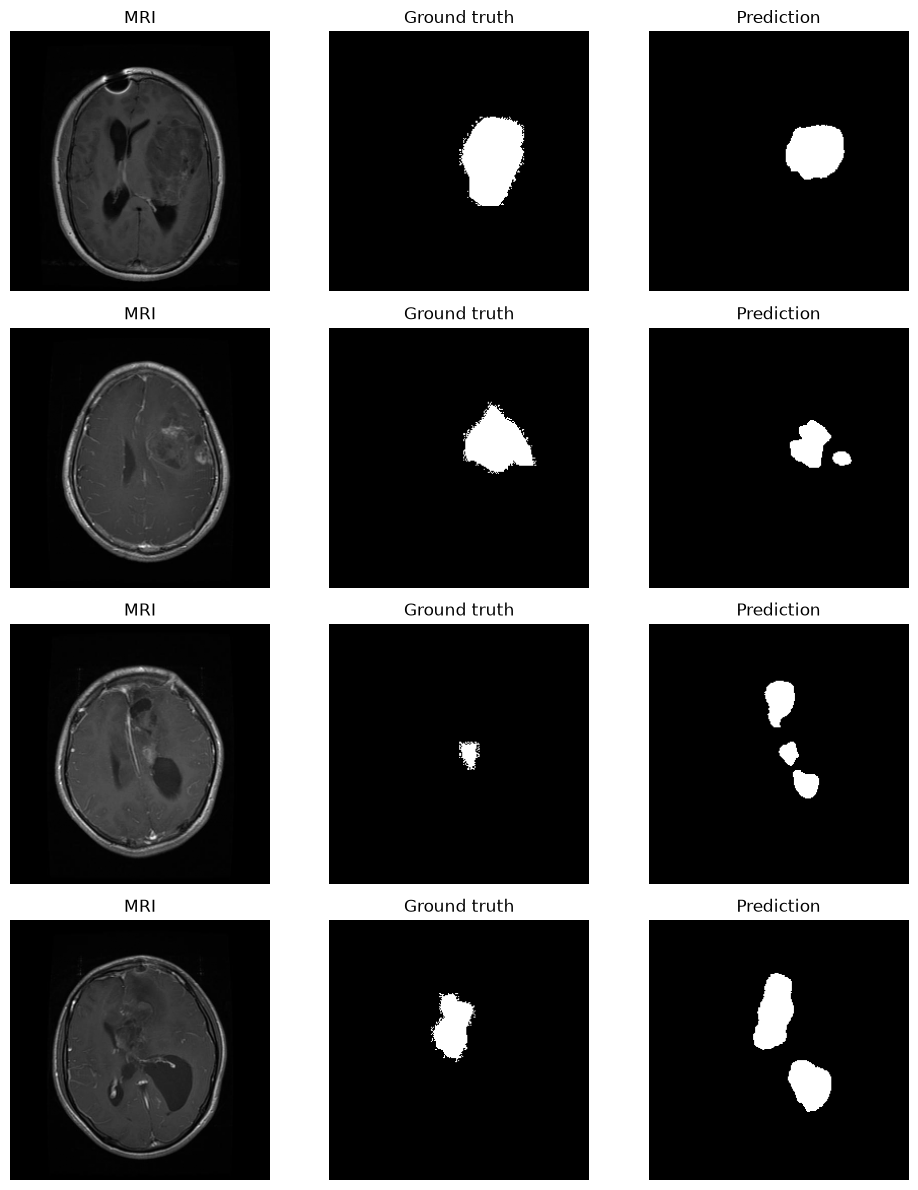

In [16]:

model.eval()

images, masks = next(iter(val_loader))
with torch.no_grad():
    probabilities = torch.sigmoid(model(images.to(device))).cpu()

predictions = (probabilities >= 0.5).float()
count = min(4, len(images))
fig, axes = plt.subplots(count, 3, figsize=(10, 3 * count))

if count == 1:
    axes = axes[None, :]

for index in range(count):
    image = images[index, 0].numpy() * 0.5 + 0.5
    axes[index, 0].imshow(image, cmap="gray")
    axes[index, 0].set_title("MRI")
    axes[index, 1].imshow(masks[index, 0], cmap="gray")
    axes[index, 1].set_title("Ground truth")
    axes[index, 2].imshow(predictions[index, 0], cmap="gray")
    axes[index, 2].set_title("Prediction")

for axis in axes.flat:
    axis.axis("off")

plt.tight_layout()
plt.show()